<a href="https://www.kaggle.com/code/hamzabilici/titanic-kaggle-submission?scriptVersionId=358285618" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

Veri seti boyutu: 891 satir, 19 sutun
   passengerid  survived  pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   
5            6         0       3   
6            7         0       1   
7            8         0       3   
8            9         1       3   
9           10         1       2   

                                                name     sex   age  sibsp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   
5                                   Moran, Mr. James    male   NaN      0   
6                         

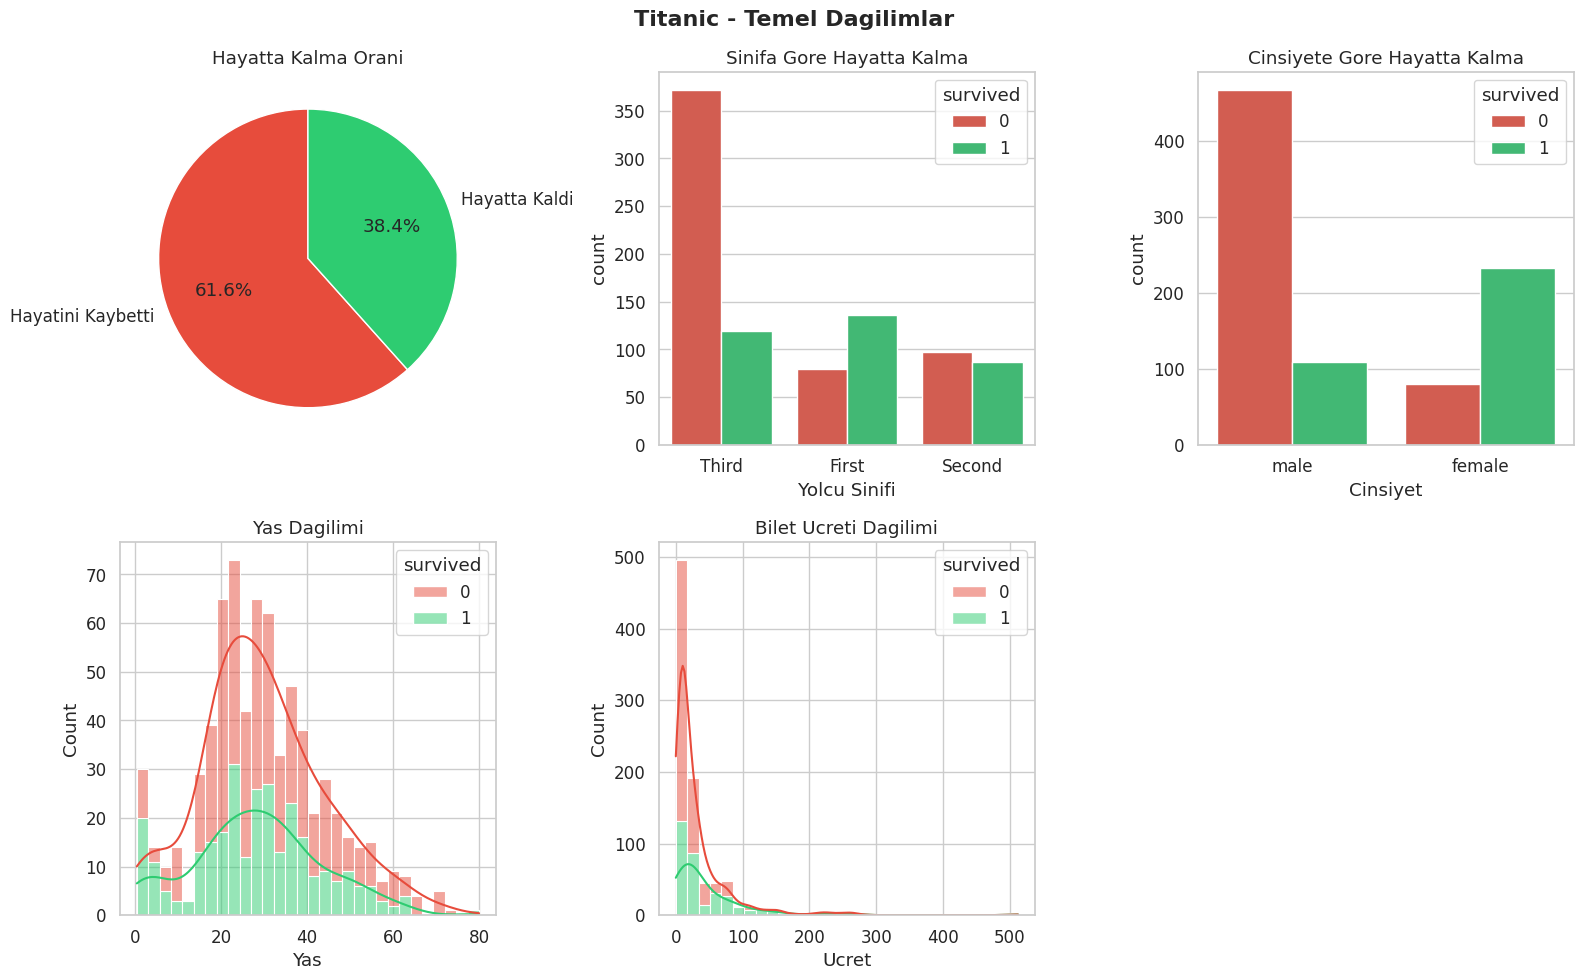

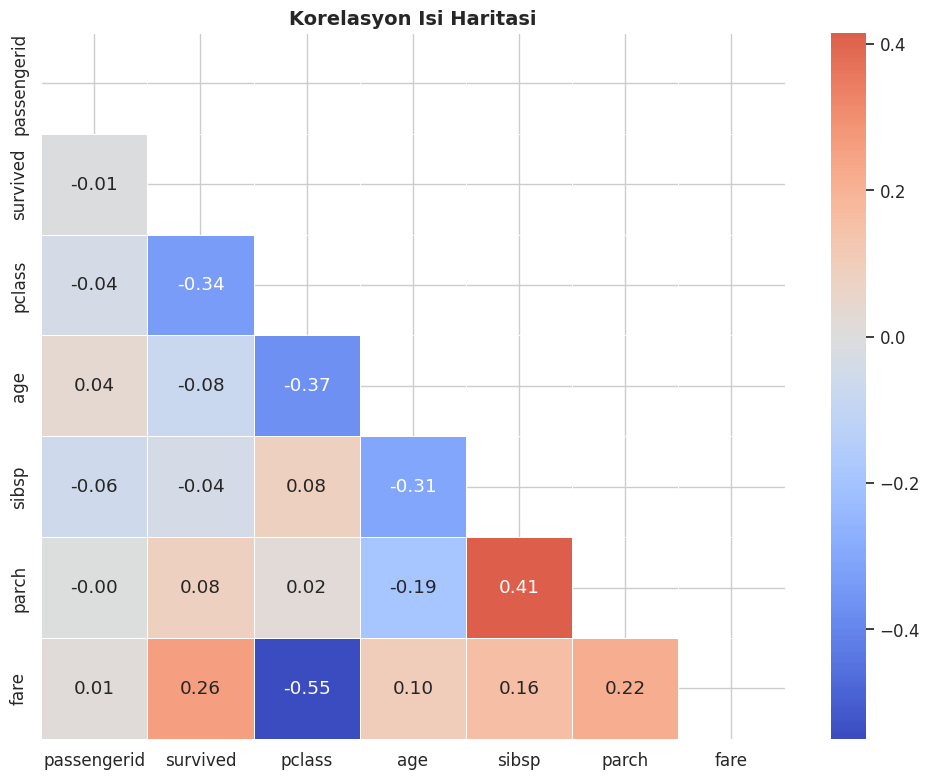

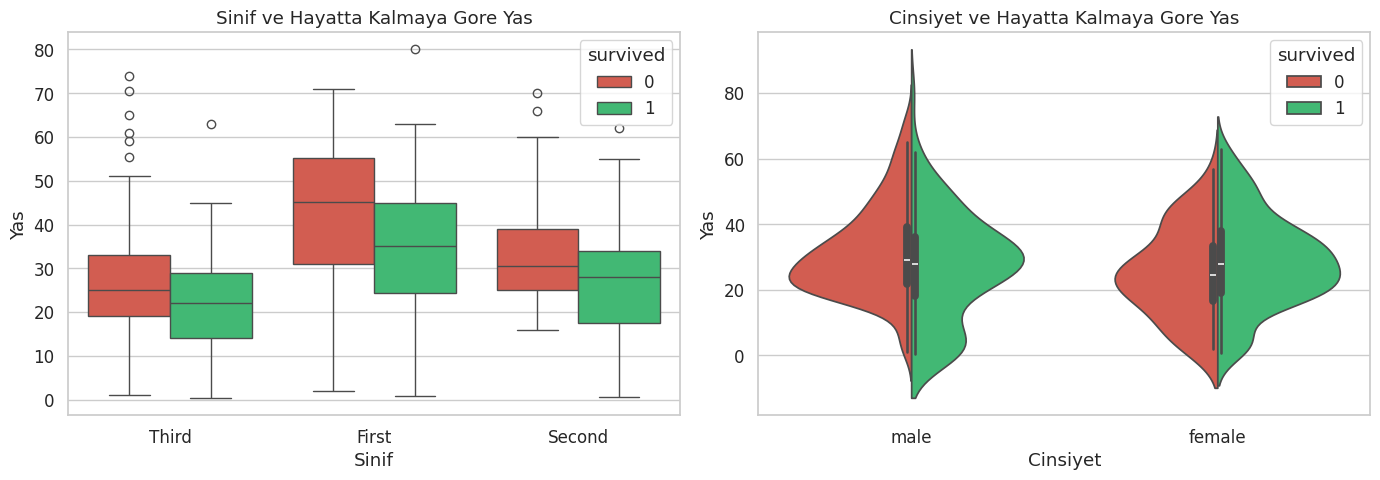

--- Sosyal Durum Dagilimi ---
SocialStatus
man_other       418
woman_other     180
man_1st         119
woman_1st        91
child_female     43
child_male       40
Name: count, dtype: int64

--- Sosyal Durum Bazinda Hayatta Kalma ---
              Hayatta Kalma Orani  Kisi Sayisi
SocialStatus                                  
woman_1st                   0.978           91
child_female                0.651           43
woman_other                 0.644          180
child_male                  0.525           40
man_1st                     0.353          119
man_other                   0.110          418


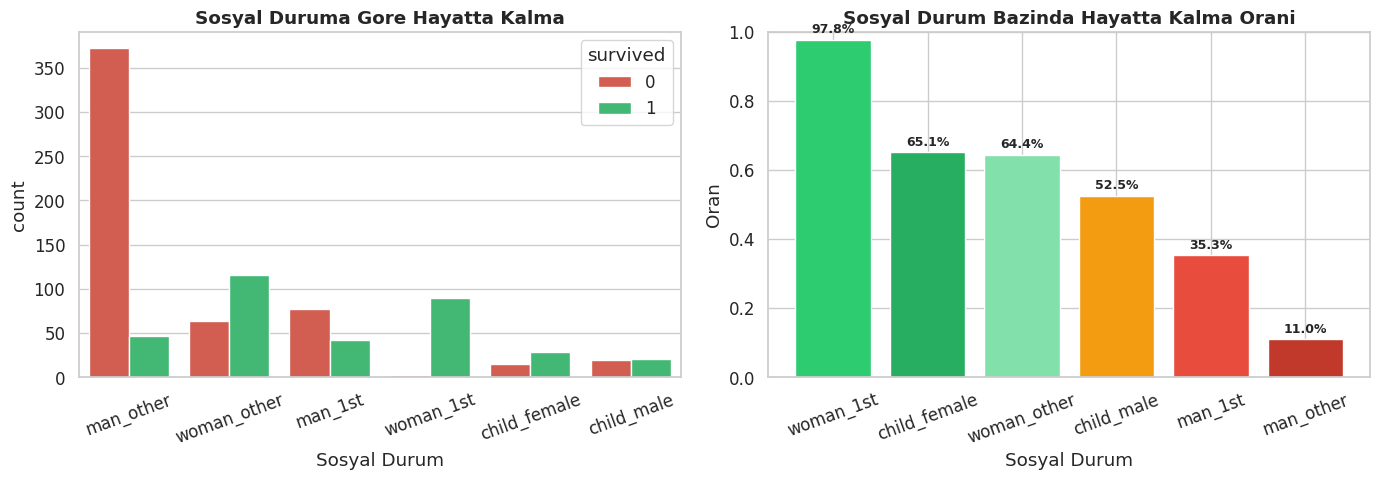

FamilySize dagilimi : {1: 537, 2: 161, 3: 102, 4: 29, 5: 15, 6: 22, 7: 12, 8: 6, 11: 7}
FarePerPerson - ort : 19.92, std: 35.84


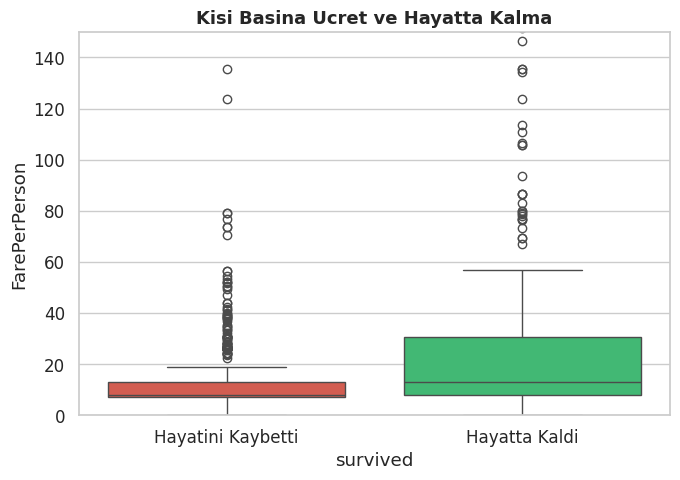

Sinif 3, male: 94 eksik -> medyan 25
Sinif 3, female: 42 eksik -> medyan 22
Sinif 1, male: 21 eksik -> medyan 40
Sinif 1, female: 9 eksik -> medyan 35
Sinif 2, male: 9 eksik -> medyan 30
Sinif 2, female: 2 eksik -> medyan 28

Kalan eksik deger (train): 1378
Ozellik sayisi : 5
Toplam ornek   : 891
Hayatta kalan  : 38.38%

Ozellikler: ['Sex_enc', 'age', 'fare', 'FarePerPerson', 'Status_enc']
=== 5-Fold Cross-Validation Sonuclari ===

Lojistik Regresyon:
* Accuracy : 0.7834
* Precision: 0.7736
* Recall   : 0.7651
* F1-Score : 0.7677

KNN (k=5):
* Accuracy : 0.7979
* Precision: 0.7867
* Recall   : 0.7853
* F1-Score : 0.7860

Random Forest:
* Accuracy : 0.8507
* Precision: 0.8474
* Recall   : 0.8341
* F1-Score : 0.8391

Lojistik Regresyon:
* Accuracy : 0.7834

KNN (k=5):
* Accuracy : 0.7979

Random Forest:
* Accuracy : 0.8507


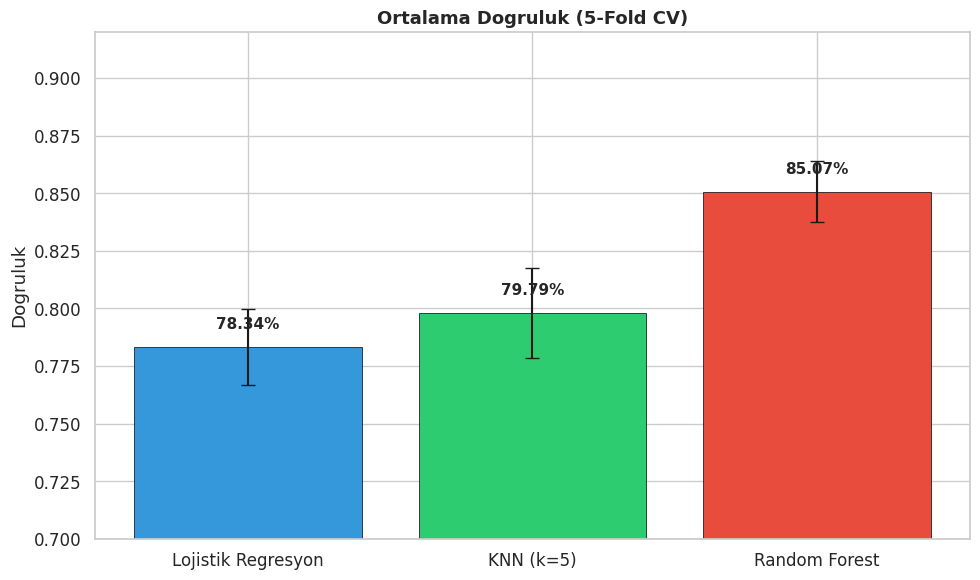

En Iyi Model: Random Forest (85.07%)


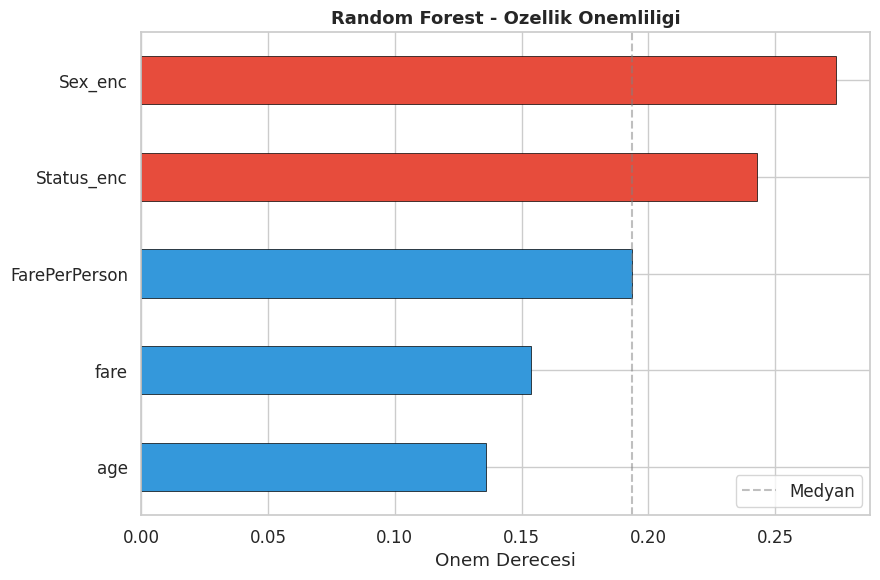


En onemli 5 ozellik:
  age                 : 0.1361
  fare                : 0.1537
  FarePerPerson       : 0.1935
  Status_enc          : 0.2428
  Sex_enc             : 0.2739

En az onemli 3 ozellik (cikarmak dusunulebilir):
  age                 : 0.1361
  fare                : 0.1537
  FarePerPerson       : 0.1935

Submission kaydedildi: submission.csv (418 satir)
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1
5          897         0
6          898         0
7          899         0
8          900         1
9          901         0


In [1]:
# ============================================================
# Titanic Veri Seti - Kapsamli Analiz & Kaggle Submission
# ============================================================
# 1. Kesifsel Veri Analizi (EDA)
# 2. Ozellik Muhendisligi (Feature Engineering)
# 3. Makine Ogrenmesi Modelleri
# 4. Kaggle Submission Olusturma

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)

# ─────────────────────────────────────────────────────────────
# Kaggle CSV'den yukle ve seaborn titanic dataset sutunlarini
# yeniden olustur (who, class, embark_town, alive, alone, deck)
# ─────────────────────────────────────────────────────────────
train_raw = pd.read_csv('/kaggle/input/competitions/titanic/train.csv')
test_raw  = pd.read_csv('/kaggle/input/competitions/titanic/test.csv')

def prepare_df(raw, is_train=True):
    df = raw.copy()
    # Sutun adlarini kucuk harfe cevir
    df.columns = [c.lower() for c in df.columns]
    # sibsp / parch / passengerid
    df.rename(columns={'passengerid': 'passengerid'}, inplace=True)

    # seaborn titanic dataset ile uyumlu turetilmis sutunlar
    df['class']       = df['pclass'].map({1: 'First', 2: 'Second', 3: 'Third'})
    df['embark_town'] = df['embarked'].map({'C': 'Cherbourg', 'Q': 'Queenstown', 'S': 'Southampton'})
    df['deck']        = df['cabin'].str[0] if 'cabin' in df.columns else np.nan

    if is_train:
        df['alive'] = df['survived'].map({0: 'no', 1: 'yes'})

    # who: child (age<16), woman, man
    def get_who(row):
        if pd.isna(row['age']):
            return 'man' if row['sex'] == 'male' else 'woman'
        if row['age'] < 16:
            return 'child'
        return 'man' if row['sex'] == 'male' else 'woman'

    df['who']        = df.apply(get_who, axis=1)
    df['adult_male'] = (df['sex'] == 'male') & (df['age'].fillna(99) >= 16)
    df['alone']      = (df['sibsp'] + df['parch']) == 0

    return df

df   = prepare_df(train_raw, is_train=True)
test = prepare_df(test_raw,  is_train=False)

print(f'Veri seti boyutu: {df.shape[0]} satir, {df.shape[1]} sutun')
print(df.head(10))

# ─────────────────────────────────────────────────────────────
# Temel Istatistikler
# ─────────────────────────────────────────────────────────────
print(df.describe(include='all').round(2))

# ─────────────────────────────────────────────────────────────
# Eksik Deger Analizi
# ─────────────────────────────────────────────────────────────
missing     = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df  = pd.DataFrame({'Eksik': missing, 'Yuzde(%)': missing_pct})
print(missing_df[missing_df['Eksik'] > 0].sort_values('Yuzde(%)', ascending=False))

# ─────────────────────────────────────────────────────────────
# Hayatta Kalma Dagilimlari
# ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Titanic - Temel Dagilimlar', fontsize=16, fontweight='bold')

survived_counts = df['survived'].value_counts()
axes[0,0].pie(survived_counts, labels=['Hayatini Kaybetti','Hayatta Kaldi'],
              autopct='%1.1f%%', colors=['#e74c3c','#2ecc71'], startangle=90)
axes[0,0].set_title('Hayatta Kalma Orani')

sns.countplot(data=df, x='class', hue='survived', ax=axes[0,1], palette=['#e74c3c','#2ecc71'])
axes[0,1].set_title('Sinifa Gore Hayatta Kalma')
axes[0,1].set_xlabel('Yolcu Sinifi')

sns.countplot(data=df, x='sex', hue='survived', ax=axes[0,2], palette=['#e74c3c','#2ecc71'])
axes[0,2].set_title('Cinsiyete Gore Hayatta Kalma')
axes[0,2].set_xlabel('Cinsiyet')

sns.histplot(data=df, x='age', hue='survived', kde=True, bins=30, ax=axes[1,0],
             palette=['#e74c3c','#2ecc71'], multiple='stack')
axes[1,0].set_title('Yas Dagilimi')
axes[1,0].set_xlabel('Yas')

sns.histplot(data=df, x='fare', hue='survived', kde=True, bins=30, ax=axes[1,1],
             palette=['#e74c3c','#2ecc71'], multiple='stack')
axes[1,1].set_title('Bilet Ucreti Dagilimi')
axes[1,1].set_xlabel('Ucret')
fig.delaxes(axes[1,2])
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────
# Korelasyon Isi Haritasi
# ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, ax=ax)
ax.set_title('Korelasyon Isi Haritasi', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────
# Yas Analizleri (Box Plot & Violin Plot)
# ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='class', y='age', hue='survived', ax=axes[0], palette=['#e74c3c','#2ecc71'])
axes[0].set_title('Sinif ve Hayatta Kalmaya Gore Yas')
axes[0].set_xlabel('Sinif'); axes[0].set_ylabel('Yas')

# split=True seaborn 0.13+ icin inner='quart' + split ile saglanir;
# eski ve yeni surumlerle uyumlu sarici:
try:
    sns.violinplot(data=df, x='sex', y='age', hue='survived', split=True,
                   ax=axes[1], palette=['#e74c3c','#2ecc71'])
except TypeError:
    sns.violinplot(data=df, x='sex', y='age', hue='survived',
                   inner='quart', ax=axes[1], palette=['#e74c3c','#2ecc71'])
axes[1].set_title('Cinsiyet ve Hayatta Kalmaya Gore Yas')
axes[1].set_xlabel('Cinsiyet'); axes[1].set_ylabel('Yas')

plt.tight_layout()
plt.show()

# ==============================================================
# BOLUM 2: OZELLIK MUHENDISLIGI
# ==============================================================

# ─────────────────────────────────────────────────────────────
# Sosyal Durum (SocialStatus) Ozellik Cikarimi
# ─────────────────────────────────────────────────────────────
def extract_social_status(row):
    who, pclass = row['who'], row['pclass']
    if who == 'child':
        return 'child_female' if row['sex'] == 'female' else 'child_male'
    elif who == 'woman':
        return 'woman_1st' if pclass == 1 else 'woman_other'
    else:  # man
        return 'man_1st' if pclass == 1 else 'man_other'

df['SocialStatus'] = df.apply(extract_social_status, axis=1)
print('--- Sosyal Durum Dagilimi ---')
print(df['SocialStatus'].value_counts())

status_survival = df.groupby('SocialStatus')['survived'].agg(['mean','count']).round(3)
status_survival.columns = ['Hayatta Kalma Orani', 'Kisi Sayisi']
print('\n--- Sosyal Durum Bazinda Hayatta Kalma ---')
print(status_survival.sort_values('Hayatta Kalma Orani', ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
status_order = df['SocialStatus'].value_counts().index
sns.countplot(data=df, x='SocialStatus', hue='survived', order=status_order,
              ax=axes[0], palette=['#e74c3c','#2ecc71'])
axes[0].set_title('Sosyal Duruma Gore Hayatta Kalma', fontweight='bold')
axes[0].set_xlabel('Sosyal Durum')
axes[0].tick_params(axis='x', rotation=20)

status_rates = df.groupby('SocialStatus')['survived'].mean().sort_values(ascending=False)
colors = ['#2ecc71','#27ae60','#82e0aa','#f39c12','#e74c3c','#c0392b']
bars = axes[1].bar(status_rates.index, status_rates.values, color=colors[:len(status_rates)])
axes[1].set_title('Sosyal Durum Bazinda Hayatta Kalma Orani', fontweight='bold')
axes[1].set_xlabel('Sosyal Durum')
axes[1].set_ylabel('Oran')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=20)
for bar, val in zip(bars, status_rates.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f'{val:.1%}', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────
# Turetilmis Ozellikler
# ─────────────────────────────────────────────────────────────
df['FamilySize']   = df['sibsp'] + df['parch'] + 1
df['FarePerPerson'] = df['fare'] / df['FamilySize']

print(f'FamilySize dagilimi : {df["FamilySize"].value_counts().sort_index().to_dict()}')
print(f'FarePerPerson - ort : {df["FarePerPerson"].mean():.2f}, std: {df["FarePerPerson"].std():.2f}')

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, x='survived', y='FarePerPerson', ax=ax,
            palette=['#e74c3c', '#2ecc71'])
ax.set_title('Kisi Basina Ucret ve Hayatta Kalma', fontsize=13, fontweight='bold')
ax.set_xticklabels(['Hayatini Kaybetti', 'Hayatta Kaldi'])
ax.set_ylabel('FarePerPerson')
ax.set_ylim(0, 150)
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────
# Eksik Veri Yonetimi - Train
# ─────────────────────────────────────────────────────────────
for pclass in df['pclass'].unique():
    for sex in df['sex'].unique():
        mask       = (df['pclass'] == pclass) & (df['sex'] == sex) & (df['age'].isnull())
        median_age = df.loc[(df['pclass'] == pclass) & (df['sex'] == sex), 'age'].median()
        df.loc[mask, 'age'] = median_age
        if mask.sum() > 0:
            print(f'Sinif {pclass}, {sex}: {mask.sum()} eksik -> medyan {median_age:.0f}')

df['fare']          = df['fare'].fillna(df['fare'].median())
df['FarePerPerson'] = df['fare'] / df['FamilySize']
print(f'\nKalan eksik deger (train): {df.isnull().sum().sum()}')

# ==============================================================
# BOLUM 3: MAKINE OGRENMESI
# ==============================================================
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing   import LabelEncoder, StandardScaler
from sklearn.linear_model    import LogisticRegression
from sklearn.ensemble        import RandomForestClassifier
from sklearn.neighbors       import KNeighborsClassifier

le = LabelEncoder()
df['Sex_enc']    = le.fit_transform(df['sex'])
df['Status_enc'] = le.fit_transform(df['SocialStatus'])

features = [
    'Sex_enc',
    'age',
    'fare',
    'FarePerPerson',
    'Status_enc',
]

X = df[features].values
y = df['survived'].values

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'Ozellik sayisi : {len(features)}')
print(f'Toplam ornek   : {len(y)}')
print(f'Hayatta kalan  : {y.mean():.2%}')
print(f'\nOzellikler: {features}')

# ─────────────────────────────────────────────────────────────
# 5-Fold Cross-Validation
# ─────────────────────────────────────────────────────────────
models = {
    'Lojistik Regresyon': LogisticRegression(max_iter=1000, random_state=42),
    'KNN (k=5)'         : KNeighborsClassifier(n_neighbors=5),
    'Random Forest'     : RandomForestClassifier(
        n_estimators=500, min_samples_split=2, max_features='log2',
        max_depth=6, criterion='gini', bootstrap=True, random_state=42, n_jobs=-1
    )
}

cv      = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

print('=== 5-Fold Cross-Validation Sonuclari ===')
for name, model in models.items():
    data    = X_scaled if name in ['Lojistik Regresyon', 'KNN (k=5)'] else X
    results = cross_validate(model, data, y, cv=cv, scoring=scoring)
    print(f"\n{name}:")
    print(f"* Accuracy : {results['test_accuracy'].mean():.4f}")
    print(f"* Precision: {results['test_precision_macro'].mean():.4f}")
    print(f"* Recall   : {results['test_recall_macro'].mean():.4f}")
    print(f"* F1-Score : {results['test_f1_macro'].mean():.4f}")

# ─────────────────────────────────────────────────────────────
# Model Karsilastirma Grafikleri
# ─────────────────────────────────────────────────────────────
accuracy_results = {}
for name, model in models.items():
    data = X_scaled if name in ['Lojistik Regresyon', 'KNN (k=5)'] else X
    res  = cross_validate(model, data, y, cv=cv, scoring=scoring)
    print(f"\n{name}:")
    print(f"* Accuracy : {res['test_accuracy'].mean():.4f}")
    accuracy_results[name] = res['test_accuracy']

fig, ax  = plt.subplots(figsize=(10, 6))
means    = {k: v.mean() for k, v in accuracy_results.items()}
stds     = {k: v.std()  for k, v in accuracy_results.items()}
colors   = ['#3498db', '#2ecc71', '#e74c3c']

bars = ax.bar(
    means.keys(), means.values(),
    yerr=list(stds.values()),
    color=colors[:len(means)],
    capsize=5, edgecolor='black', linewidth=0.5
)
ax.set_title('Ortalama Dogruluk (5-Fold CV)', fontsize=13, fontweight='bold')
ax.set_ylabel('Dogruluk')
ax.set_ylim(0.7, 0.92)
for bar, val in zip(bars, means.values()):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.008,
            f'{val:.2%}', ha='center', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────
# En Iyi Model ve Ozellik Onemliligi
# ─────────────────────────────────────────────────────────────
best_name  = max(means, key=means.get)
print(f'En Iyi Model: {best_name} ({means[best_name]:.2%})')

best_model = models[best_name]
best_data  = X_scaled if 'Lojistik' in best_name or 'KNN' in best_name else X
best_model.fit(best_data, y)

if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
    feat_imp    = pd.Series(importances, index=features).sort_values(ascending=True)

    fig, ax     = plt.subplots(figsize=(9, 6))
    colors_bar  = ['#e74c3c' if imp > feat_imp.median() else '#3498db'
                   for imp in feat_imp.values]
    feat_imp.plot(kind='barh', color=colors_bar, edgecolor='black', linewidth=0.5, ax=ax)
    ax.set_title(f'{best_name} - Ozellik Onemliligi', fontsize=13, fontweight='bold')
    ax.set_xlabel('Onem Derecesi')
    ax.axvline(feat_imp.median(), color='gray', linestyle='--', alpha=0.5, label='Medyan')
    ax.legend()
    plt.tight_layout()
    plt.show()

    print('\nEn onemli 5 ozellik:')
    for feat, imp in feat_imp.tail(5).items():
        print(f'  {feat:20s}: {imp:.4f}')
    print('\nEn az onemli 3 ozellik (cikarmak dusunulebilir):')
    for feat, imp in feat_imp.head(3).items():
        print(f'  {feat:20s}: {imp:.4f}')

# ==============================================================
# BOLUM 4: KAGGLE SUBMISSION
# ==============================================================

# Test seti icin ayni on islemeleri uygula
test['SocialStatus'] = test.apply(extract_social_status, axis=1)
test['FamilySize']   = test['sibsp'] + test['parch'] + 1

# Eksik veri: yas (train medyanlari kullan - data leakage onlenir)
for pclass in test['pclass'].unique():
    for sex in test['sex'].unique():
        mask       = (test['pclass'] == pclass) & (test['sex'] == sex) & (test['age'].isnull())
        median_age = df.loc[(df['pclass'] == pclass) & (df['sex'] == sex), 'age'].median()
        test.loc[mask, 'age'] = median_age

test['fare']          = test['fare'].fillna(df['fare'].median())
test['FarePerPerson'] = test['fare'] / test['FamilySize']

# Encoding (train'in le'si ile fit edilmis)
le_sex    = LabelEncoder().fit(df['sex'])
le_status = LabelEncoder().fit(df['SocialStatus'])

test['Sex_enc']    = le_sex.transform(test['sex'])
test['Status_enc'] = le_status.transform(test['SocialStatus'])

X_test     = test[features].values
X_test_std = scaler.transform(X_test)   # train scaler'i ile transform

best_X_test = X_test_std if 'Lojistik' in best_name or 'KNN' in best_name else X_test
predictions  = best_model.predict(best_X_test)

submission = pd.DataFrame({
    'PassengerId': test_raw['PassengerId'],
    'Survived'   : predictions.astype(int)
})
submission.to_csv('submission.csv', index=False)
print(f'\nSubmission kaydedildi: submission.csv ({len(submission)} satir)')
print(submission.head(10))